In [1]:
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.image import ImageDataGenerator as IDG
import kagglehub
from sklearn.metrics import (accuracy_score,log_loss, classification_report,confusion_matrix,ConfusionMatrixDisplay)
import matplotlib.pyplot as plt

2026-10-27 11:30:30.158151: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
/opt/anaconda3/envs/Emotion-Recognition/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
path = kagglehub.dataset_download("msambare/fer2013")

In [3]:
model_path = "/Users/juanarnold/Documents/Master's Degree/Semester 1/Neural Networks/Projects/Emotion/Realtime-Emotion-Recognition/backend/utils/model/emotion_classifier.keras"

In [4]:
model = load_model(model_path)

2026-10-27 11:30:44.822020: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [5]:
model.summary()

Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d_8 (Conv2D)           (None, 46, 46, 32)        320       
                                                                 
 conv2d_9 (Conv2D)           (None, 44, 44, 64)        18496     
                                                                 
 max_pooling2d_6 (MaxPooling  (None, 22, 22, 64)       0         
 2D)                                                             
                                                                 
 dropout_6 (Dropout)         (None, 22, 22, 64)        0         
                                                                 
 conv2d_10 (Conv2D)          (None, 20, 20, 128)       73856     
                                                                 
 max_pooling2d_7 (MaxPooling  (None, 10, 10, 128)      0         
 2D)                                                  

In [6]:
val_dir = "/Users/juanarnold/.cache/kagglehub/datasets/msambare/fer2013/versions/1/test"

batch_size = 64

datagen = IDG(rescale=1./255)

validation_generator = datagen.flow_from_directory(
        val_dir,
        target_size=(48,48),
        batch_size=batch_size,
        color_mode="grayscale",
        class_mode='categorical',
        shuffle=False)

Found 7178 images belonging to 7 classes.


113/113 [==============================] - 14s 126ms/step
Accuracy: 0.6564502646976874
Loss: 0.9389056508708531
              precision    recall  f1-score   support

       angry     0.5750    0.5762    0.5756       958
     disgust     0.7391    0.3063    0.4331       111
        fear     0.5329    0.3877    0.4488      1024
       happy     0.8399    0.8839    0.8613      1774
     neutral     0.5810    0.6894    0.6306      1233
         sad     0.5269    0.5180    0.5224      1247
    surprise     0.7635    0.8002    0.7814       831

    accuracy                         0.6565      7178
   macro avg     0.6512    0.5945    0.6076      7178
weighted avg     0.6515    0.6565    0.6500      7178



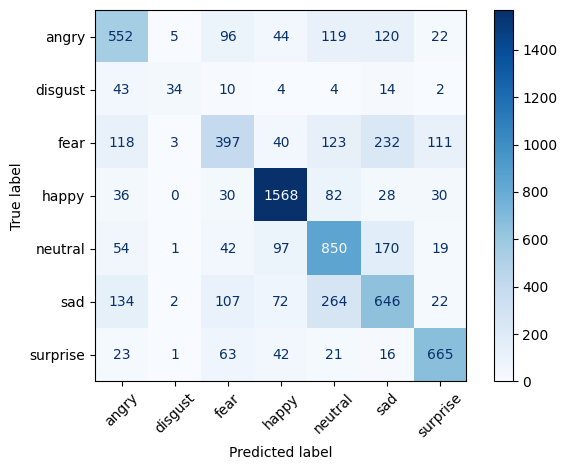

In [7]:
# Get model predictions
y_prob = model.predict(validation_generator, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Ground-truth labels (categorical one-hot encoded)
y_true = validation_generator.classes

# Get class names in the correct index order
class_names = [
    name for name, index in sorted(
        validation_generator.class_indices.items(),
        key=lambda item: item[1]
    )
]

# Accuracy & Loss
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Loss:", log_loss(y_true, y_prob, labels=np.arange(y_prob.shape[1])))

# Precision, recall, F1-score for every emotion
print(classification_report(y_true,y_pred,labels=np.arange(len(class_names)),target_names=class_names,zero_division=0,digits=4))

# Confusion matrix
cm = confusion_matrix(y_true,y_pred,labels=np.arange(len(class_names)))
disp = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.tight_layout()
plt.show()